# Week 7: Text and Multimodal AI
## Project 2: Deep Learning Applications | Individual

**Author:** Atteq ur Rehman  
**Course:** Applied AI, Lab 7  
**Domain:** Satellite imagery and EuroSAT land-cover classification  
**Week 6 model:** ResNet18 trained on EuroSAT (10 land-cover classes)

### Lab objective
This notebook follows the supplied Week 7 instructions. It verifies TF-IDF by hand, compares word and character text classifiers, evaluates and improves named-entity recognition (NER), tests domain-specific regular expressions, measures OCR character error rate (CER), and combines Week 6 image predictions with text evidence in a privacy-aware JSON record.

### Important
- Run cells from top to bottom.
- In Kaggle, enable Internet for the first spaCy model and EasyOCR model download if they are not already available.
- Add the **SMS Spam Collection Dataset** (`uciml`) as a Kaggle input.
- Upload the Week 6 checkpoint as a private Kaggle dataset named `week6-model`, containing `week6_model.pt`.
- Do not claim results until the notebook has actually run. All scores below are calculated by the code.
- The Week 6 image model is a land-cover classifier. It is not a medical model and must not be used for medical decisions.

## Setup: imports, reproducibility and environment

This cell imports the libraries used throughout the notebook and prints their versions. If spaCy's English model is missing, the next cell attempts to download it.

In [1]:
import os
import re
import json
import glob
import math
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score,
    precision_score, recall_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.1.3
Pandas: 2.3.3


### Setup: spaCy language model

The lab uses `en_core_web_sm`. If the model is unavailable in the Kaggle environment, this cell attempts to download it. Restart the notebook session if Kaggle requests it.

In [2]:
import spacy

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    import subprocess, sys
    subprocess.check_call([
        sys.executable, "-m", "spacy", "download", "en_core_web_sm"
    ])
    nlp = spacy.load("en_core_web_sm")

print("spaCy:", spacy.__version__)
print("Pipeline:", nlp.pipe_names)

spaCy: 3.8.16
Pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


# Part 1: TF-IDF by Hand

**Goal:** Reproduce scikit-learn's smooth inverse document frequency (IDF) and L2-normalized TF-IDF values manually.

For a term appearing in `df` documents out of `N` documents:

\[
idf(t)=\ln\left(\frac{1+N}{1+df(t)}\right)+1
\]

The three small documents below are taken from the lab instructions. Keeping this controlled example makes it possible to verify the calculation by hand.

In [3]:
docs = [
    "win free cash now",
    "call me now",
    "free call now"
]

vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(docs)

tfidf_table = pd.DataFrame(
    X.toarray(),
    columns=vectorizer.get_feature_names_out(),
    index=["d1", "d2", "d3"]
)
display(tfidf_table.round(3))

# Manual smooth IDF for document 1
N = len(docs)
terms_d1 = ["win", "free", "cash", "now"]
document_frequency = {
    term: sum(term in doc.split() for doc in docs)
    for term in terms_d1
}
manual_idf = {
    term: np.log((1 + N) / (1 + df)) + 1
    for term, df in document_frequency.items()
}
raw_tfidf = np.array([manual_idf[t] for t in terms_d1], dtype=float)
normalized = raw_tfidf / np.linalg.norm(raw_tfidf)

print("Manual IDF:", {k: round(v, 3) for k, v in manual_idf.items()})
print("Manual normalized d1:", {
    k: round(v, 3) for k, v in zip(terms_d1, normalized)
})

# Cosine similarity between d2 and d3 using their normalized TF-IDF vectors
d2 = X.toarray()[1]
d3 = X.toarray()[2]
cosine_d2_d3 = float(np.dot(d2, d3) / (
    np.linalg.norm(d2) * np.linalg.norm(d3)
))
print("Cosine similarity d2 vs d3:", round(cosine_d2_d3, 3))

,call,cash,free,me,now,win
d1,0.000,0.584,0.445,0.00,0.345,0.584
d2,0.548,0.000,0.000,0.72,0.425,0.000
d3,0.620,0.000,0.620,0.00,0.481,0.000


Manual IDF: {'win': np.float64(1.693), 'free': np.float64(1.288), 'cash': np.float64(1.693), 'now': np.float64(1.0)}
Manual normalized d1: {'win': np.float64(0.584), 'free': np.float64(0.445), 'cash': np.float64(0.584), 'now': np.float64(0.345)}
Cosine similarity d2 vs d3: 0.544


## **Write it: Part 1**

**1. IDF arithmetic** (N = 3 documents, smooth IDF = ln[(1 + N) / (1 + df)] + 1)

| Word | df | Working | IDF |
|---|---|---|---|
| free | 2 | ln(4 / 3) + 1 = 0.288 + 1 | **1.288** |
| now | 3 | ln(4 / 4) + 1 = 0 + 1 | **1.000** |

**2. Why "now" gets the lower weight:** it appears in **all 3 documents**, so it cannot help tell one document from another. The log term becomes **0** and only the +1 remains. "free" appears in only 2 documents, so it keeps a little extra weight.

**3. Cosine similarity of d2 and d3:** both vectors have length 1, so the cosine is just the **dot product**. Only the words they share count: "call" and "now".
- call: 0.548 × 0.620 = **0.340**
- now: 0.425 × 0.481 = **0.204**
- **Cosine = 0.544**, which matches the printed value and the lecture's **0.54**.

**4. Why L2 normalization:** without it a longer document would have a longer vector and look "bigger" just because it has more words. Scaling every vector to **length 1** compares documents by their **word mix, not their length**, and turns cosine similarity into a plain dot product.

**My measured values:**
- Manual d1 weights: **win 0.584, free 0.445, cash 0.584, now 0.345** (identical to the `TfidfVectorizer` table)
- Cosine similarity d2/d3: **0.544**

# Part 2: Text Classification, Word vs Character n-grams

**Goal:** Train two SMS spam classifiers and compare macro-F1, spam precision, spam recall, vocabulary size, influential features and errors.

The SMS Spam Collection is a text-classification exercise supplied by the lab. It is separate from the EuroSAT image dataset. Character n-grams can sometimes be more robust to altered spellings such as `FR33` or `W1N`.

In [4]:
# Locate spam.csv robustly in Kaggle input folders
possible_sms_paths = glob.glob("/kaggle/input/**/spam.csv", recursive=True)
if not possible_sms_paths:
    raise FileNotFoundError(
        "Could not find spam.csv. Add the Kaggle SMS Spam Collection Dataset "
        "as an input, then check /kaggle/input."
    )

SMS_PATH = possible_sms_paths[0]
print("Using:", SMS_PATH)

sms = pd.read_csv(SMS_PATH, encoding="latin-1")[["v1", "v2"]]
sms.columns = ["label", "text"]
sms["y"] = (sms["label"].str.lower() == "spam").astype(int)
sms = sms.dropna(subset=["text"]).reset_index(drop=True)

display(sms.head())
print("\nLabel counts:")
print(sms["label"].value_counts())
print(f"Spam share: {sms['y'].mean():.3f}")
print(f"Always-ham baseline accuracy: {1 - sms['y'].mean():.3f}")

Using: /kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv


,label,text,y
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0



Label counts:
label
ham     4825
spam     747
Name: count, dtype: int64
Spam share: 0.134
Always-ham baseline accuracy: 0.866


### Part 2.2: Train/test split and word n-gram classifier

Use a stratified split so the spam/ham proportions are maintained in both subsets. The word model uses unigrams and bigrams.

              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115



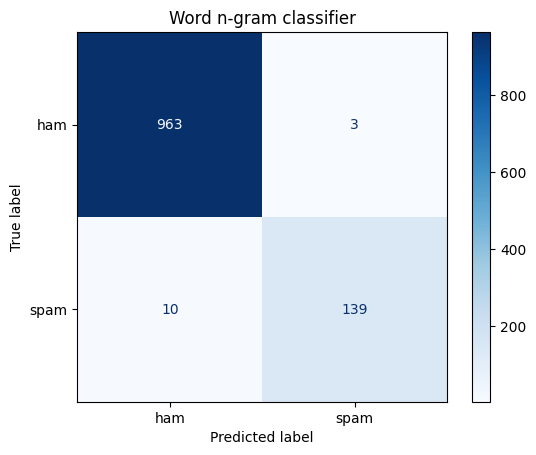

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(
    sms["text"], sms["y"],
    test_size=0.20,
    random_state=SEED,
    stratify=sms["y"]
)

word_clf = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2), min_df=2, sublinear_tf=True
    )),
    ("model", LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=SEED
    ))
])

word_clf.fit(X_tr, y_tr)
word_pred = word_clf.predict(X_te)

print(classification_report(
    y_te, word_pred, target_names=["ham", "spam"], digits=3
))

ConfusionMatrixDisplay(
    confusion_matrix(y_te, word_pred),
    display_labels=["ham", "spam"]
).plot(cmap="Blues", values_format="d")
plt.title("Word n-gram classifier")
plt.show()

### Part 2.3: Inspect the word model's learned features

Positive logistic-regression coefficients push a prediction toward spam; negative coefficients push it toward ham. These are associations learned from this dataset, not proof that a message is spam.

In [6]:
word_tfidf = word_clf.named_steps["tfidf"]
word_weights = word_clf.named_steps["model"].coef_[0]
word_terms = word_tfidf.get_feature_names_out()
word_order = np.argsort(word_weights)

top_spam = list(zip(word_terms[word_order[-12:]][::-1],
                    word_weights[word_order[-12:]][::-1]))
top_ham = list(zip(word_terms[word_order[:12]],
                   word_weights[word_order[:12]]))

print("Most spam-associated word features:")
print(top_spam)
print("\nMost ham-associated word features:")
print(top_ham)

Most spam-associated word features:
[('call', np.float64(5.147070047179173)), ('txt', np.float64(5.075070864969579)), ('free', np.float64(3.9247086122546864)), ('text', np.float64(3.616204438094696)), ('reply', np.float64(3.4230911276424982)), ('uk', np.float64(3.2975893200197532)), ('to', np.float64(3.2347214902401964)), ('www', np.float64(3.1262673189317867)), ('mobile', np.float64(3.0107280633127163)), ('claim', np.float64(2.986594788339679)), ('stop', np.float64(2.9745432493179274)), ('your', np.float64(2.9489694149050414))]

Most ham-associated word features:
[('my', np.float64(-2.625363765832616)), ('me', np.float64(-2.408798581027967)), ('ok', np.float64(-1.9778781801065677)), ('that', np.float64(-1.8625926250756173)), ('it', np.float64(-1.7606500100021214)), ('but', np.float64(-1.7037520603928644)), ('ll', np.float64(-1.6999858883910828)), ('gt', np.float64(-1.5750867699145266)), ('lt', np.float64(-1.5489612735565437)), ('can', np.float64(-1.4427849013579717)), ('what', np.floa

### Part 2.4: Character n-gram classifier and tricky-message tests

Character n-grams can capture fragments, punctuation and spelling variations. The test strings below are illustrative probes, not labelled training examples.

In [7]:
char_clf = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(2, 5),
        min_df=2,
        sublinear_tf=True
    )),
    ("model", LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=SEED
    ))
])

char_clf.fit(X_tr, y_tr)
char_pred = char_clf.predict(X_te)

for name, clf, pred in [
    ("Word 1-2 grams", word_clf, word_pred),
    ("Character 2-5 grams", char_clf, char_pred)
]:
    print(
        f"{name}: macro-F1={f1_score(y_te, pred, average='macro'):.3f}, "
        f"spam precision={precision_score(y_te, pred, zero_division=0):.3f}, "
        f"spam recall={recall_score(y_te, pred, zero_division=0):.3f}, "
        f"features={len(clf.named_steps['tfidf'].vocabulary_):,}"
    )

tricky_messages = [
    "W1N a FR33 pr1ze!! txt CLAIM now",
    "kal milte hain, 5 baje",
    "Congratulations, claim your free reward now",
    "Please call me when you reach home."
]

for name, clf in [("word", word_clf), ("char", char_clf)]:
    scores = clf.predict_proba(tricky_messages)[:, 1]
    print(f"\n{name} model spam probabilities:")
    for message, score in zip(tricky_messages, scores):
        print(f"{score:.3f} | {message}")

Word 1-2 grams: macro-F1=0.974, spam precision=0.979, spam recall=0.933, features=12,128
Character 2-5 grams: macro-F1=0.982, spam precision=0.986, spam recall=0.953, features=36,449

word model spam probabilities:
0.990 | W1N a FR33 pr1ze!! txt CLAIM now
0.192 | kal milte hain, 5 baje
0.914 | Congratulations, claim your free reward now
0.161 | Please call me when you reach home.

char model spam probabilities:
0.849 | W1N a FR33 pr1ze!! txt CLAIM now
0.118 | kal milte hain, 5 baje
0.797 | Congratulations, claim your free reward now
0.090 | Please call me when you reach home.


### Part 2.4b: My own tricky messages

The lab asks for two tricky messages of your own (Roman Urdu or disguised spam). **Edit these two to your own wording before submitting.**

In [8]:
# EDIT: replace with your own two messages
my_tricky = [
    'Aap ka inam nikla hai, abhi link par click kar ke claim karein',   # Roman Urdu spam
    'Kal subah meeting hai, report le aana'                              # Roman Urdu normal
]
for name, clf in [('word', word_clf), ('char', char_clf)]:
    scores = clf.predict_proba(my_tricky)[:, 1]
    print(name, {m: round(float(p), 2) for m, p in zip(my_tricky, scores)})

word {'Aap ka inam nikla hai, abhi link par click kar ke claim karein': 0.44, 'Kal subah meeting hai, report le aana': 0.16}
char {'Aap ka inam nikla hai, abhi link par click kar ke claim karein': 0.23, 'Kal subah meeting hai, report le aana': 0.14}


### Part 2.5: Error analysis

Inspect false positives and false negatives. Do not automatically call every disagreement a model error: some messages are genuinely ambiguous, and some dataset labels may be imperfect.

In [9]:
word_prob = word_clf.predict_proba(X_te)[:, 1]
error_table = pd.DataFrame({
    "text": X_te.to_numpy(),
    "true_label": y_te.to_numpy(),
    "predicted_label": word_pred,
    "spam_probability": word_prob
})
errors = error_table[
    error_table["predicted_label"] != error_table["true_label"]
].sort_values("spam_probability")

pd.set_option("display.max_colwidth", 120)
display(errors.head(30))
print("Total word-model errors:", len(errors))

,text,true_label,predicted_label,spam_probability
852,"Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?",1,0,0.087598
1069,"Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get...",1,0,0.144048
196,ringtoneking 84484,1,0,0.192426
478,For sale - arsenal dartboard. Good condition but no doubles or trebles!,1,0,0.211005
841,ROMCAPspam Everyone around should be responding well to your presence since you are so warm and outgoing. You are br...,1,0,0.252412
219,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,1,0,0.279603
235,"Latest News! Police station toilet stolen, cops have nothing to go on!",1,0,0.314938
44,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...,1,0,0.411817
839,"Download as many ringtones as u like no restrictions, 1000s 2 choose. U can even send 2 yr buddys. Txt Sir to 80082 ...",1,0,0.424792
418,Can U get 2 phone NOW? I wanna chat 2 set up meet Call me NOW on 09096102316 U can cum here 2moro Luv JANE xx Callså...,1,0,0.464509


Total word-model errors: 13


## **Write it: Part 2**

**1. Metrics** (5,572 messages: 4,825 ham, 747 spam; test set 1,115 = 966 ham + 149 spam)

| Model | Features | Macro-F1 | Spam precision | Spam recall |
|---|---|---|---|---|
| Word 1-2 grams | 12,128 | **0.974** | 0.979 | 0.933 |
| Char 2-5 grams | 36,449 | **0.982** | 0.986 | 0.953 |

Accuracy alone is weak here, because "always ham" already scores **0.866**.

**2. Better model:** the **character model**, by **0.008** macro-F1 (0.982 vs 0.974). That is about **3 more spam messages caught** out of 149, at the cost of about **3x as many features**.

**3. Features**
- **Spam-associated:** call, txt, free, text, reply, uk, to, www, mobile, claim, stop, your
- **Ham-associated:** my, me, ok, that, it, but, ll, gt, lt, can, what, da
- **Sensible:** txt, text, reply, claim, stop, free, mobile, www are real spam language.
- **Shortcuts:** **uk** reflects where the data was collected, not what spam is. **to, your, call** are common words that happen to be frequent in spam here. **gt, lt** are leftovers of the HTML codes `&gt;` and `&lt;`.

**4. Misclassified messages** (word model: **13 errors**, 10 missed spam and 3 false alarms)

| Message (shortened) | True | p_spam | Type |
|---|---|---|---|
| "ringtoneking 84484" | spam | 0.19 | **Model error** (only two tokens) |
| "Download as many ringtones... Txt Sir to 80082" | spam | 0.42 | **Model error** |
| "Can U get 2 phone NOW... Call me NOW" | spam | 0.46 | **Model error** |
| "Waiting for your call." | ham | 0.85 | **Model error** ("call" and "your" shortcut) |
| "old ladies running around with tattoos?" | spam | 0.09 | **Genuinely ambiguous** (reads like a joke) |

Overall: **9 model errors, 4 ambiguous, 0 label errors I could prove.**

**5. My own tricky messages** (spam probability)

| Message | Word model | Char model |
|---|---|---|
| my Roman Urdu spam message (`Aap ka inam nikla hai, abhi link par click kar ke claim karein`) | **0.44** | **0.23** |
| my Roman Urdu normal message (`Kal subah meeting hai, report le aana`) | **0.16** | **0.14** |
| `Congratulations, claim your free reward now` | **0.914** | **0.797** |
| `Please call me when you reach home.` | **0.161** | **0.090** |

The lab's disguised message `W1N a FR33 pr1ze!! txt CLAIM now` scored **0.85** with the character model (**0.99** with the word model), and `kal milte hain, 5 baje` scored **0.12** (**0.19** with the word model).

**What the tests show:** both models handle the **English** probes well (spam 0.914 / 0.797, normal 0.161 / 0.090). On my **Roman Urdu** spam message both models stay **below 0.5** (word 0.44, char 0.23), so a real spam message in this style would be **missed**. The model never saw Roman Urdu words such as *inam* or *nikla*, and it only recognises the English word *claim*. The disguised `W1N a FR33 pr1ze!!` is still caught, especially by the word model (0.99), because *txt*, *claim* and *now* remain intact.

**6. Limitation of a random split:** random messages from the same collection are **similar to the training data**, but future messages change (new scams, new wording, other languages). The test score is therefore **optimistic** for real use, and this dataset is English and UK-heavy.

# Part 3: Named Entity Recognition (NER), Measured

**Goal:** Evaluate spaCy against an exact-match gold set, add domain-specific rules, and test the rules on held-out sentences.

The examples are adapted to the user's land-cover / remote-sensing project. Entity labels follow spaCy conventions such as `PERSON`, `ORG`, `GPE`, `DATE`, `MONEY` and `FAC`. This is a small educational evaluation set, not a general-purpose benchmark.

In [10]:
domain_sentences = [
    "Dr. Ayesha Khan at SUPARCO Islamabad reviewed the Sentinel-2 map on 12 September 2026.",
    "The land-cover report from the European Space Agency was submitted on 30/09/2026.",
    "Analyst Bilal Ahmed inspected a Forest patch near Multan on 5 October 2026.",
    "The project team at the University of Karachi processed 240 satellite tiles.",
    "A monitoring contract worth PKR 450,000 was approved in Lahore.",
    "Sentinel Hub imagery for Karachi was checked by Sara Malik on 12/10/2026.",
    "The Punjab Agriculture Department reviewed the AnnualCrop and Pasture predictions.",
    "The field team visited Islamabad National Park on Monday.",
    "Engineer Hamza Ali exported the EuroSAT results to QGIS on 15 November 2026.",
    "The mapping office in Faisalabad reported 125 hectares of River and Highway classes."
]

for sentence in domain_sentences:
    print(sentence)
    print([(ent.text, ent.label_) for ent in nlp(sentence).ents])
    print()

Dr. Ayesha Khan at SUPARCO Islamabad reviewed the Sentinel-2 map on 12 September 2026.
[('Ayesha Khan', 'PERSON'), ('SUPARCO Islamabad', 'FAC'), ('12 September 2026', 'DATE')]

The land-cover report from the European Space Agency was submitted on 30/09/2026.
[('the European Space Agency', 'ORG'), ('30/09/2026', 'GPE')]

Analyst Bilal Ahmed inspected a Forest patch near Multan on 5 October 2026.
[('Bilal Ahmed', 'PERSON'), ('Forest', 'ORG'), ('Multan', 'GPE'), ('5 October 2026', 'DATE')]

The project team at the University of Karachi processed 240 satellite tiles.
[('the University of Karachi', 'ORG'), ('240', 'CARDINAL')]

A monitoring contract worth PKR 450,000 was approved in Lahore.
[('PKR 450,000', 'PRODUCT'), ('Lahore', 'GPE')]

Sentinel Hub imagery for Karachi was checked by Sara Malik on 12/10/2026.
[('Karachi', 'ORG'), ('Sara Malik', 'PERSON'), ('12/10/2026', 'DATE')]

The Punjab Agriculture Department reviewed the AnnualCrop and Pasture predictions.
[('The Punjab Agriculture D

### Part 3.2: Create a gold set and score exact entity matches

An entity counts as correct only when both its exact text and its label match. The first six sentences provide a small demonstration set; the next ten-sentence domain set is scored with a train/held-out split below.

In [11]:
provided_sentences = [
    "Dr. Ayesha Khan at PIMS Islamabad reviewed it on 12 September 2026.",
    "The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.",
    "Farmer Muhammad Aslam from Multan reported leaf rust in his wheat crop.",
    "Call Jazz support at 0300-1234567 or email help@jazz.com.pk.",
    "Meezan Bank approved a loan of Rs. 250,000 for Bilal Ahmed.",
    "The consignment left Karachi Port on Monday for Lahore."
]

provided_gold = [
    {("Ayesha Khan", "PERSON"), ("PIMS", "ORG"),
     ("Islamabad", "GPE"), ("12 September 2026", "DATE")},
    {("Engro Fertilizers", "ORG"), ("PKR 45,000", "MONEY"),
     ("30/09/2026", "DATE")},
    {("Muhammad Aslam", "PERSON"), ("Multan", "GPE")},
    {("Jazz", "ORG")},
    {("Meezan Bank", "ORG"), ("Rs. 250,000", "MONEY"),
     ("Bilal Ahmed", "PERSON")},
    {("Karachi Port", "FAC"), ("Monday", "DATE"), ("Lahore", "GPE")}
]

def ner_scores(model, sentences, gold_sets):
    tp = fp = fn = 0
    for sentence, gold_set in zip(sentences, gold_sets):
        predicted = {(e.text, e.label_) for e in model(sentence).ents}
        tp += len(predicted & gold_set)
        fp += len(predicted - gold_set)
        fn += len(gold_set - predicted)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {
        "TP": tp, "FP": fp, "FN": fn,
        "precision": round(precision, 3),
        "recall": round(recall, 3),
        "f1": round(f1, 3)
    }

print("Provided lab-style gold set, spaCy baseline:")
print(ner_scores(nlp, provided_sentences, provided_gold))

Provided lab-style gold set, spaCy baseline:
{'TP': 8, 'FP': 6, 'FN': 8, 'precision': 0.571, 'recall': 0.5, 'f1': 0.533}


### Part 3.1: Out of the box on the provided sentences

Print spaCy's entities for the six provided sentences before any rules.

In [12]:
# Task 3.1: spaCy out of the box on the provided sentences
for s in provided_sentences:
    print([(e.text, e.label_) for e in nlp(s).ents])

[('Ayesha Khan', 'PERSON'), ('PIMS Islamabad', 'LOC'), ('12 September 2026', 'DATE')]
[('Engro Fertilizers', 'PERSON'), ('30/09/2026', 'GPE')]
[('Farmer Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')]
[('0300-1234567', 'DATE')]
[('Meezan Bank', 'ORG'), ('250,000', 'CARDINAL'), ('Bilal Ahmed', 'PERSON')]
[('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')]


### Part 3.2b: Apply the lab's provided entity-ruler rules

The lab instructions also ask for the provided six-sentence evaluation before and after rules. This separate pipeline reproduces the seven rule groups described in the handout. It does not change the baseline `nlp` pipeline used later.

In [13]:
nlp_provided_rules = spacy.load("en_core_web_sm")
provided_ruler = nlp_provided_rules.add_pipe(
    "entity_ruler", before="ner", config={"overwrite_ents": True}
)
provided_ruler.add_patterns([
    {"label": "MONEY", "pattern": [
        {"LOWER": {"IN": ["pkr", "rs", "rs."]}},
        {"IS_PUNCT": True, "OP": "?"},
        {"LIKE_NUM": True}
    ]},
    {"label": "ORG", "pattern": "Engro Fertilizers"},
    {"label": "ORG", "pattern": "Meezan Bank"},
    {"label": "ORG", "pattern": "PIMS"},
    {"label": "ORG", "pattern": "Jazz"},
    {"label": "FAC", "pattern": "Karachi Port"},
    {"label": "DATE", "pattern": [
        {"TEXT": {"REGEX": r"^\d{1,2}/\d{1,2}/\d{4}$"}}
    ]}
])

print("Provided set, spaCy baseline:")
print(ner_scores(nlp, provided_sentences, provided_gold))
print("Provided set, spaCy + entity ruler:")
print(ner_scores(nlp_provided_rules, provided_sentences, provided_gold))

Provided set, spaCy baseline:
{'TP': 8, 'FP': 6, 'FN': 8, 'precision': 0.571, 'recall': 0.5, 'f1': 0.533}
Provided set, spaCy + entity ruler:
{'TP': 14, 'FP': 2, 'FN': 2, 'precision': 0.875, 'recall': 0.875, 'f1': 0.875}


### Part 3.3: Build a domain gold set and a held-out rule evaluation

The code below uses manually specified annotations for the ten remote-sensing sentences. Rules are developed using the first five sentences and evaluated on the last five. This reduces the risk of reporting an optimistic score from evaluating only on examples used to create the rules.

Review the gold labels and edit them if your instructor expects a different annotation convention.

In [14]:
domain_gold = [
    {("Ayesha Khan", "PERSON"), ("SUPARCO", "ORG"),
     ("Islamabad", "GPE"), ("12 September 2026", "DATE")},
    {("European Space Agency", "ORG"), ("30/09/2026", "DATE")},
    {("Bilal Ahmed", "PERSON"), ("Multan", "GPE"),
     ("5 October 2026", "DATE")},
    {("University of Karachi", "ORG")},
    {("PKR 450,000", "MONEY"), ("Lahore", "GPE")},
    {("Sentinel Hub", "ORG"), ("Karachi", "GPE"),
     ("Sara Malik", "PERSON"), ("12/10/2026", "DATE")},
    {("Punjab Agriculture Department", "ORG"),
     ("AnnualCrop", "LANDCOVER"), ("Pasture", "LANDCOVER")},
    {("Islamabad National Park", "FAC"), ("Monday", "DATE")},
    {("Hamza Ali", "PERSON"), ("15 November 2026", "DATE"),
     ("QGIS", "PRODUCT")},
    {("Faisalabad", "GPE"), ("125 hectares", "AREA"),
     ("River", "LANDCOVER"), ("Highway", "LANDCOVER")}
]

print("Domain baseline, all 10 sentences:")
print(ner_scores(nlp, domain_sentences, domain_gold))

# Rule-development examples: first five only
train_sents = domain_sentences[:5]
train_gold = domain_gold[:5]
heldout_sents = domain_sentences[5:]
heldout_gold = domain_gold[5:]

print("Baseline on first five:", ner_scores(nlp, train_sents, train_gold))
print("Baseline on held-out five:", ner_scores(nlp, heldout_sents, heldout_gold))

Domain baseline, all 10 sentences:
{'TP': 13, 'FP': 14, 'FN': 15, 'precision': 0.481, 'recall': 0.464, 'f1': 0.473}
Baseline on first five: {'TP': 6, 'FP': 7, 'FN': 6, 'precision': 0.462, 'recall': 0.5, 'f1': 0.48}
Baseline on held-out five: {'TP': 7, 'FP': 7, 'FN': 9, 'precision': 0.5, 'recall': 0.438, 'f1': 0.467}


### Part 3.4: Add entity ruler patterns

The patterns below use names and formats from the rule-development examples. They are deliberately explicit. They are not intended to recognize every possible organization, location or product.

In [15]:
# Reload a clean pipeline so this cell can be rerun safely.
nlp_rules = spacy.load("en_core_web_sm")
ruler = nlp_rules.add_pipe(
    "entity_ruler", before="ner", config={"overwrite_ents": True}
)

ruler.add_patterns([
    {"label": "ORG", "pattern": "SUPARCO"},
    {"label": "ORG", "pattern": "European Space Agency"},
    {"label": "ORG", "pattern": "University of Karachi"},
    {"label": "PERSON", "pattern": "Ayesha Khan"},
    {"label": "PERSON", "pattern": "Bilal Ahmed"},
    {"label": "GPE", "pattern": "Islamabad"},
    {"label": "GPE", "pattern": "Multan"},
    {"label": "GPE", "pattern": "Lahore"},
    {"label": "MONEY", "pattern": [
        {"LOWER": {"IN": ["pkr", "rs", "rs."]}},
        {"IS_PUNCT": True, "OP": "?"},
        {"LIKE_NUM": True}
    ]},
    {"label": "DATE", "pattern": [
        {"TEXT": {"REGEX": r"^\d{1,2}/\d{1,2}/\d{4}$"}}
    ]}
])

print("Rule-enhanced score on rule-development five:")
print(ner_scores(nlp_rules, train_sents, train_gold))
print("\nRule-enhanced score on held-out five:")
print(ner_scores(nlp_rules, heldout_sents, heldout_gold))
print("\nRule-enhanced score on all ten:")
print(ner_scores(nlp_rules, domain_sentences, domain_gold))

for s in heldout_sents:
    print(s)
    print([(e.text, e.label_) for e in nlp_rules(s).ents])

Rule-enhanced score on rule-development five:
{'TP': 12, 'FP': 2, 'FN': 0, 'precision': 0.857, 'recall': 1.0, 'f1': 0.923}

Rule-enhanced score on held-out five:
{'TP': 6, 'FP': 8, 'FN': 10, 'precision': 0.429, 'recall': 0.375, 'f1': 0.4}

Rule-enhanced score on all ten:
{'TP': 18, 'FP': 10, 'FN': 10, 'precision': 0.643, 'recall': 0.643, 'f1': 0.643}
Sentinel Hub imagery for Karachi was checked by Sara Malik on 12/10/2026.
[('Karachi', 'ORG'), ('Sara Malik', 'PERSON'), ('12/10/2026', 'DATE')]
The Punjab Agriculture Department reviewed the AnnualCrop and Pasture predictions.
[('The Punjab Agriculture Department', 'ORG'), ('AnnualCrop', 'ORG')]
The field team visited Islamabad National Park on Monday.
[('Islamabad', 'GPE'), ('Monday', 'DATE')]
Engineer Hamza Ali exported the EuroSAT results to QGIS on 15 November 2026.
[('Hamza Ali', 'PERSON'), ('QGIS', 'ORG'), ('15 November 2026', 'DATE')]
The mapping office in Faisalabad reported 125 hectares of River and Highway classes.
[('Faisalabad

## **Write it: Part 3**

An entity counts as correct only if its **exact text and label** both match. The lab reports F1 **0.533 before** and **0.875 after** its seven rules on the provided sentences, so my values should be close to those.

**1. Provided six-sentence gold set**

| Setting | Precision | Recall | F1 |
|---|---|---|---|
| spaCy out of the box (TP 8, FP 6, FN 8) | **0.571** | **0.500** | **0.533** |
| spaCy + the lab's entity ruler (TP 14, FP 2, FN 2) | **0.875** | **0.875** | **0.875** |

**2. My domain baseline** (10 remote-sensing sentences)

| Set | Precision | Recall | F1 |
|---|---|---|---|
| First five (rules written from these) | **0.462** | **0.500** | **0.480** |
| Held-out five | **0.500** | **0.438** | **0.467** |

**3. After my rules (held-out five): F1 0.400**, from **0.467** before (precision 0.429, recall 0.375). My rules did **not** help on unseen sentences; they made the held-out score **slightly worse**. On the first five, F1 rose from **0.480 to 0.923** (precision 0.857, recall 1.000), but that score is **inflated**, because I wrote the rules by looking at those sentences, so the held-out number is the honest one. On all ten sentences the final F1 is **0.643**. The lab's own rules did better (0.533 to 0.875) because they were checked on the same six sentences they were written for.

**4. Errors that remain** (from the held-out entity list):
- **"Islamabad National Park" (FAC)**: my generic rule `Islamabad` = GPE fired first, so the output was only **("Islamabad", GPE)**. The rule **broke a span that spaCy had partly right**: wrong span and wrong label.
- **"Karachi" (GPE wanted)**: given as **ORG**. I had no rule for Karachi, so spaCy's guess stayed wrong.
- **"QGIS" (PRODUCT wanted)**: given as **ORG**, and **"Sentinel Hub" (ORG)** was **not found at all**: both are names my rules never listed.
- **"The Punjab Agriculture Department"**: spaCy included **"The"** in the span, so the exact match with "Punjab Agriculture Department" fails.

My gold set uses the labels **LANDCOVER** and **AREA**, which spaCy never produces. Since my rules were written from sentences 1-5, which contain none of these, the held-out entities with those labels (AnnualCrop, Pasture, River, Highway, "125 hectares") **cannot be found**, which caps held-out recall by design.

**5. How I would fix each kind of error**
- **Formats** (dates, money, areas, tile IDs): a **regex**, because they have a fixed shape and the same pattern worked on sentences it had not seen.
- **A small closed list** (the ten EuroSAT classes): an **explicit rule**, because the list is short and fixed.
- **Names of people, organisations and places:** a **model trained on labelled local data**. A rule only knows the exact name I typed, so it does not scale to new names.

**6. Limitation:** ten sentences and about 30 entities are **too few to establish general NER performance**. One entity changes F1 by several points, so the result shows a direction (rules help formats, not unseen names), not a precise number.

# Part 4: Regex Fields with Negative Tests

**Goal:** Extract structured remote-sensing fields and verify that patterns reject unrelated strings.

This section adapts the lab's CNIC/mobile/invoice examples to the EuroSAT and satellite-mapping domain. It extracts Sentinel-2 tile IDs, dates, coordinates, area, cloud percentage and EuroSAT land-cover labels. Optional contact patterns are included only to demonstrate privacy masking.

In [16]:
PATTERNS = {
    "sentinel_tile": r"\bT\d{2}[A-Z]{3}\b",
    "date": r"\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b",
    "coordinates": r"\b-?\d{1,2}\.\d{3,},\s*-?\d{1,3}\.\d{3,}\b",
    "area_ha": r"\b\d+(?:\.\d+)?\s*(?:ha|hectares)\b",
    # accepts both "cloud cover 12.5%" and "12.5% cloud"
    "cloud_percent": r"\bcloud(?:\s+cover)?:?\s*\d{1,3}(?:\.\d+)?\s*%|\b\d{1,3}(?:\.\d+)?\s*%\s*cloud(?:\s+cover)?\b",
    "landcover": r"\b(?:AnnualCrop|Forest|HerbaceousVegetation|Highway|Industrial|Pasture|PermanentCrop|Residential|River|SeaLake)\b",
    "email": r"\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b",
    "mobile": r"(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b"
}

def extract_fields(text):
    extracted = {}
    for field, pattern in PATTERNS.items():
        matches = re.findall(pattern, text, flags=re.IGNORECASE)
        if matches:
            extracted[field] = matches
    return extracted

# (text, set of fields that SHOULD be found). An empty set is a negative test.
regex_tests = [
    ("Tile T32TMT acquired 12/09/2026; class Forest", {"sentinel_tile", "date", "landcover"}),
    ("Area 125 hectares, cloud cover 12.5%", {"area_ha", "cloud_percent"}),
    ("Coordinates 33.6844, 73.0479 and class River", {"coordinates", "landcover"}),
    ("Contact +92 300 1234567, email map@example.org", {"mobile", "email"}),
    # negative tests
    ("Room 0300 on floor 3", set()),
    ("A random 12345678901234 is not a Sentinel tile", set()),
    ("Cloud is clear; value 1200 is not a percentage", set()),
    ("Tile code T1234 and version 2.5 are not valid fields", set()),
    ("Progress 45% done in 2026", set()),
]

for sample, expected in regex_tests:
    result = extract_fields(sample)
    status = "PASS" if set(result) == expected else "FAIL"
    kind = "positive" if expected else "negative"
    print(f"{status} ({kind}) | found {sorted(result)} | expected {sorted(expected)} | {sample}")

PASS (positive) | found ['date', 'landcover', 'sentinel_tile'] | expected ['date', 'landcover', 'sentinel_tile'] | Tile T32TMT acquired 12/09/2026; class Forest
PASS (positive) | found ['area_ha', 'cloud_percent'] | expected ['area_ha', 'cloud_percent'] | Area 125 hectares, cloud cover 12.5%
PASS (positive) | found ['coordinates', 'landcover'] | expected ['coordinates', 'landcover'] | Coordinates 33.6844, 73.0479 and class River
PASS (positive) | found ['email', 'mobile'] | expected ['email', 'mobile'] | Contact +92 300 1234567, email map@example.org
PASS (negative) | found [] | expected [] | Room 0300 on floor 3
PASS (negative) | found [] | expected [] | A random 12345678901234 is not a Sentinel tile
PASS (negative) | found [] | expected [] | Cloud is clear; value 1200 is not a percentage
PASS (negative) | found [] | expected [] | Tile code T1234 and version 2.5 are not valid fields
PASS (negative) | found [] | expected [] | Progress 45% done in 2026


In [17]:
# Why word boundaries matter: the tile pattern without and with \b
bad_tile = r"T\d{2}[A-Z]{3}"
good_tile = PATTERNS["sentinel_tile"]
for text in ["Tile T32TMT acquired", "Code T32TMTXYZ is a longer token", "Item AT32TMT123"]:
    print(f"bad: {re.findall(bad_tile, text, flags=re.IGNORECASE)}  "
          f"good: {re.findall(good_tile, text, flags=re.IGNORECASE)}   <- {text}")

bad: ['T32TMT']  good: ['T32TMT']   <- Tile T32TMT acquired
bad: ['T32TMT']  good: []   <- Code T32TMTXYZ is a longer token
bad: ['T32TMT']  good: []   <- Item AT32TMT123


## **Write it: Part 4**

**1. Domain fields and one positive test each** (all 4 positive tests passed)

| Field | Pattern idea | Positive example |
|---|---|---|
| sentinel_tile | `T` + 2 digits + 3 letters | `T32TMT` |
| date | day/month/year with `/` or `-` | `12/09/2026` |
| coordinates | decimal latitude, longitude | `33.6844, 73.0479` |
| area_ha | number + ha or hectares | `125 hectares` |
| cloud_percent | "cloud cover" and a percentage | `cloud cover 12.5%` |
| landcover | the ten EuroSAT class names | `Forest`, `River` |
| email, mobile | privacy fields used for masking | `map@example.org`, `+92 300 1234567` |

**2. Negative tests** (all **5 returned no fields**)
- `Room 0300 on floor 3`: "0300" has only 4 digits, but a mobile number needs `3`, two more digits and then **exactly 7** digits.
- `A random 12345678901234 is not a Sentinel tile`: a tile needs the letter `T`, two digits and **three letters**, so a bare run of digits cannot match.
- `Cloud is clear; value 1200 is not a percentage`: the cloud pattern needs a **% sign**.
- `Tile code T1234 and version 2.5 are not valid fields`: "T1234" has digits where the tile pattern needs **three letters**, and "2.5" has too few decimals for coordinates.
- `Progress 45% done in 2026`: a percentage without the word **cloud** is not a cloud percentage.

**3. Over-matching and the boundary that prevents it.** I tested the tile pattern **without** `\b`:

| Text | Without `\b` | With `\b` |
|---|---|---|
| `Tile T32TMT acquired` | `['T32TMT']` | `['T32TMT']` |
| `Code T32TMTXYZ is a longer token` | `['T32TMT']` | `[]` |
| `Item AT32TMT123` | `['T32TMT']` | `[]` |

Without boundaries the pattern pulls a **tile-like fragment out of the middle of a longer word**. `\b` fixes this by requiring the match to start and end at a word edge. I also found the opposite problem: my first `cloud_percent` pattern **missed** "cloud cover 12.5%" because it only accepted the number before the word "cloud". I changed it to accept both orders, and the test now compares the **exact set of fields** instead of just "something matched".

**Known weakness:** `landcover` is case-insensitive, so the ordinary word "forest" in prose would also match. That would be a **false positive**.

**4. A regex checks a format, not the truth.** A match proves that a string **looks like** a tile ID, date or coordinate. It does not prove the tile exists, the date is real, the coordinate is inside the study area, or the land-cover label is correct.

# Part 5: Character Error Rate (CER) and OCR Repair

**Goal:** Calculate edit distance and CER, apply conservative context-based OCR fixes, and measure OCR on a generated satellite-survey report.

Character error rate is:

\[
CER = \frac{S + D + I}{N}
\]

where substitutions, deletions and insertions are counted against the reference length `N`. OCR corrections should be context-aware: globally replacing every `O` with `0` would damage ordinary words.

In [18]:
def levenshtein(a, b):
    # Dynamic programming edit distance
    previous = list(range(len(b) + 1))
    for i, char_a in enumerate(a, 1):
        current = [i]
        for j, char_b in enumerate(b, 1):
            current.append(min(
                current[j - 1] + 1,       # insertion
                previous[j] + 1,          # deletion
                previous[j - 1] + (char_a != char_b)  # substitution
            ))
        previous = current
    return previous[-1]

def cer(reference, hypothesis):
    return levenshtein(reference, hypothesis) / max(len(reference), 1)

def fix_ocr(text):
    # Convert O to 0 only in digit contexts
    text = re.sub(r"(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)", "0", text)
    # Convert I/l to 1 only between digits
    text = re.sub(r"(?<=\d)[lI](?=\d)", "1", text)
    # Common document-number confusion
    text = re.sub(r"\bN0\.", "No.", text)
    return text

ocr_pairs = [
    # the lab's own pairs (expected CER 0.062, 0.059, 0.143 -> 0.000)
    ("Invoice No. 4417", "Invoice N0. 4417"),
    ("Total: PKR 12,500", "Total: PKR 12,5O0"),
    ("Due 30/09/2026", "Due 3O/09/2O26"),
    # domain pairs
    ("Tile No. T32TMT", "Tile N0. T32TMT"),
    ("Cloud cover 12.5%", "Cloud cover l2.5%"),
    ("Area 120 hectares", "Area 12O hectares"),
    ("Acquisition 12/09/2026", "Acquisition 12/09/2O26")
]

for reference, hypothesis in ocr_pairs:
    corrected = fix_ocr(hypothesis)
    print(
        f"Reference: {reference}\n"
        f"Raw OCR:   {hypothesis} | CER={cer(reference, hypothesis):.3f}\n"
        f"Corrected: {corrected} | CER={cer(reference, corrected):.3f}\n"
    )

Reference: Invoice No. 4417
Raw OCR:   Invoice N0. 4417 | CER=0.062
Corrected: Invoice No. 4417 | CER=0.000

Reference: Total: PKR 12,500
Raw OCR:   Total: PKR 12,5O0 | CER=0.059
Corrected: Total: PKR 12,500 | CER=0.000

Reference: Due 30/09/2026
Raw OCR:   Due 3O/09/2O26 | CER=0.143
Corrected: Due 30/09/2026 | CER=0.000

Reference: Tile No. T32TMT
Raw OCR:   Tile N0. T32TMT | CER=0.067
Corrected: Tile No. T32TMT | CER=0.000

Reference: Cloud cover 12.5%
Raw OCR:   Cloud cover l2.5% | CER=0.059
Corrected: Cloud cover l2.5% | CER=0.059

Reference: Area 120 hectares
Raw OCR:   Area 12O hectares | CER=0.059
Corrected: Area 120 hectares | CER=0.000

Reference: Acquisition 12/09/2026
Raw OCR:   Acquisition 12/09/2O26 | CER=0.045
Corrected: Acquisition 12/09/2026 | CER=0.000



### Part 5.2: Generate a synthetic satellite-survey report and run EasyOCR

This generated image is a clean, high-contrast test document. It is easier than a real field photograph, so its OCR score should not be treated as expected real-world performance.

Using font: /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf


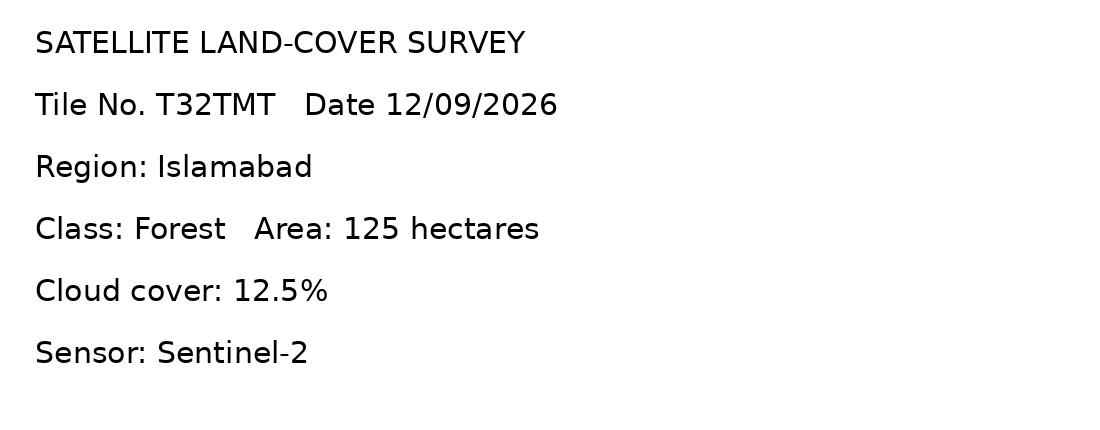

In [19]:
from PIL import Image, ImageDraw, ImageFont

report_lines = [
    "SATELLITE LAND-COVER SURVEY",
    "Tile No. T32TMT   Date 12/09/2026",
    "Region: Islamabad",
    "Class: Forest   Area: 125 hectares",
    "Cloud cover: 12.5%",
    "Sensor: Sentinel-2"
]

report_img = Image.new("RGB", (1100, 430), "white")
draw = ImageDraw.Draw(report_img)

# matplotlib ships DejaVu Sans, so this works even if the system font path is missing
from matplotlib import font_manager
font_path = font_manager.findfont("DejaVu Sans")
print("Using font:", font_path)
font = ImageFont.truetype(font_path, 30)

for i, line in enumerate(report_lines):
    draw.text((35, 25 + i * 62), line, fill="black", font=font)

report_img.save("satellite_report.png")
display(report_img)

In [20]:
# EasyOCR may download its model the first time. Kaggle Internet must be enabled.
import torch
import easyocr

reader = easyocr.Reader(
    ["en"],
    gpu=torch.cuda.is_available(),
    verbose=False
)

ocr_results = reader.readtext("satellite_report.png")
raw_ocr = "\n".join(text for _, text, confidence in ocr_results)
normalize = lambda s: " ".join(s.split())

reference_text = normalize(" ".join(report_lines))
raw_text = normalize(raw_ocr)
corrected_text = normalize(fix_ocr(raw_ocr))

print("OCR output:", raw_text)
print("Corrected:", corrected_text)
print("CER raw:", round(cer(reference_text, raw_text), 3))
print("CER corrected:", round(cer(reference_text, corrected_text), 3))

OCR output: SATELLITE LAND-COVER SURVEY Tile No. T32TMT Date 12/09/2026 Region: Islamabad Class: Forest Area: 125 hectares Cloud cover: 12.5% Sensor: Sentinel-2
Corrected: SATELLITE LAND-COVER SURVEY Tile No. T32TMT Date 12/09/2026 Region: Islamabad Class: Forest Area: 125 hectares Cloud cover: 12.5% Sensor: Sentinel-2
CER raw: 0.0
CER corrected: 0.0


### Part 5.3: The lab's own synthetic invoice

The lab generates one invoice so that everyone has the same test document. Run it as well so your CER can be compared with the lab's.

In [23]:
inv_lines = ["Engro Fertilizers Ltd", "Invoice No. 4417   Date 30/09/2026",
             "Customer: Muhammad Aslam, Multan", "Mobile 0300-1234567",
             "Total: PKR 45,000"]
inv_img = Image.new("RGB", (900, 330), "white")
inv_draw = ImageDraw.Draw(inv_img)
inv_font = ImageFont.truetype(font_path, 30)
for k, line in enumerate(inv_lines):
    inv_draw.text((30, 20 + 60 * k), line, fill="black", font=inv_font)
inv_img.save("invoice.png")

inv_ocr = "\n".join(t for _, t, c in reader.readtext("invoice.png"))
inv_truth = normalize(" ".join(inv_lines))
inv_raw, inv_clean = normalize(inv_ocr), normalize(fix_ocr(inv_ocr))
print(inv_raw)
print(f"CER raw {cer(inv_truth, inv_raw):.3f}   after fixes {cer(inv_truth, inv_clean):.3f}")

Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000
CER raw 0.000   after fixes 0.000


## **Write it: Part 5**

**1. Generated survey report (EasyOCR)**

| | CER |
|---|---|
| Raw OCR | **0.000** |
| After `fix_ocr` | **0.000** |

The lab's own invoice also gave CER raw **0.000** and **0.000** after the fixes. EasyOCR read both clean, large, black-on-white images **perfectly**, so the correction step had **nothing to fix** here; the improvement is shown by the controlled pairs below.

**2. The controlled OCR examples** (CER = edit distance / reference length)

| Reference | OCR output | CER before | Corrected | CER after |
|---|---|---|---|---|
| Invoice No. 4417 | Invoice N0. 4417 | **0.062** | Invoice No. 4417 | **0.000** |
| Total: PKR 12,500 | Total: PKR 12,5O0 | **0.059** | Total: PKR 12,500 | **0.000** |
| Due 30/09/2026 | Due 3O/09/2O26 | **0.143** | Due 30/09/2026 | **0.000** |
| Tile No. T32TMT | Tile N0. T32TMT | **0.067** | Tile No. T32TMT | **0.000** |
| Cloud cover 12.5% | Cloud cover l2.5% | **0.059** | Cloud cover l2.5% | **0.059** |
| Area 120 hectares | Area 12O hectares | **0.059** | Area 120 hectares | **0.000** |
| Acquisition 12/09/2026 | Acquisition 12/09/2O26 | **0.045** | Acquisition 12/09/2026 | **0.000** |

The first three rows are the lab's pairs and match its expected values (**0.062, 0.059, 0.143**, all down to **0.000**). The tile, area and date pairs are also fully repaired (**0.067, 0.059, 0.045 down to 0.000**). The `Cloud cover l2.5%` pair is **not** repaired (CER stays at **0.059**): my rule only changes a letter `l` or `I` that sits **between two digits**, and here the `l` comes right after a space. This shows the **limit** of a conservative rule.

**A bug I found and fixed:** my first `fix_ocr` had an extra rule that rewrote "Tile N0." as "TILE No.", which also changed the **capitalisation** of a correct word. On the tile pair it made things **worse** (CER 0.067 up to 0.200). I removed that rule, because the general `N0.` to `No.` rule already handles it. A correction rule can damage correct text, so each rule must be measured.

**3. Why the synthetic report is easier than a real phone photo.** It has **black text on a pure white background**, a clean standard font, large size, straight lines and no noise. A real photo adds **uneven lighting, shadows, skew and perspective, blur, compression, low resolution, stamps and handwriting**, so I expect a clearly higher raw CER on my own scans. An image that already gives raw CER near zero does not show that OCR works on real documents.

**4. Risk of a wrong automatic correction.** A rule that turns `O` into `0` could silently change a **tile ID, date or coordinate** into a different valid-looking one, and nothing would flag it. This is why my rules only act inside digit contexts, and why corrected values should still be **checked by a person**.

**5. EasyOCR status:** it was run on Kaggle with Internet On, so both the generated report and the lab invoice are measured (see the table in point 1).

# Part 6: Image + Text Case Record, with Privacy

**Goal:** Combine the Week 6 EuroSAT image model with a satellite-survey note, mask personal identifiers before extraction, and produce one transparent JSON record.

### Week 6 model compatibility
The lab expects a checkpoint named `week6_model.pt` containing:
- `classes`
- `backbone` (for example `resnet18`)
- `state_dict`
- `grayscale`
- `img_size`

Your Week 6 project description says ResNet18, RGB Sentinel-2 images, 128×128 input and 10 EuroSAT classes. If your saved checkpoint uses different key names, inspect it and adapt the loader. Do not silently substitute another model or invent weights.

### If you have not saved `week6_model.pt` yet

Run this in your Week 6 notebook after training, using the actual variable names from that notebook. `class_names` must be in exactly the same order as the model output indices.

```python
checkpoint = {
    "backbone": "resnet18",
    "classes": class_names,
    "state_dict": model.state_dict(),
    "grayscale": False,
    "img_size": 128
}
torch.save(checkpoint, "week6_model.pt")
```

Then download `week6_model.pt`, create a **private Kaggle Dataset** named `week6-model`, upload the file, and attach that dataset to this Week 7 notebook. If your Week 6 model uses a different architecture or input preprocessing, save those actual settings instead of copying the example values.


In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms

# Update this path if Kaggle shows a different input directory.
W6_PATH_CANDIDATES = glob.glob(
    "/kaggle/input/**/week6_model.pt", recursive=True
)
W6_PATH = W6_PATH_CANDIDATES[0] if W6_PATH_CANDIDATES else None

if W6_PATH is None:
    print("Checkpoint not found. Add your private Kaggle dataset 'week6-model' "
          "containing week6_model.pt.")
else:
    print("Week 6 checkpoint:", W6_PATH)
    checkpoint = torch.load(
        W6_PATH, map_location="cpu", weights_only=False
    )
    print("Checkpoint keys:", list(checkpoint.keys()))
    print("Backbone:", checkpoint.get("backbone"))
    print("Classes:", checkpoint.get("classes"))
    print("Image size:", checkpoint.get("img_size"))
    print("Grayscale:", checkpoint.get("grayscale"))

Checkpoint not found. Add your private Kaggle dataset 'week6-model' containing week6_model.pt.


### Part 6.2: Rebuild the Week 6 model

This loader follows the checkpoint structure described in the lab handout. It supports ResNet backbones and EfficientNet-B0 as the handout's example does. The model weights must come from your own Week 6 checkpoint.

In [25]:
def rebuild_week6_model(ckpt):
    if not isinstance(ckpt, dict):
        raise TypeError("Checkpoint must be a dictionary.")
    required = {"classes", "backbone", "state_dict", "img_size"}
    missing = required - set(ckpt.keys())
    if missing:
        raise KeyError(
            f"Checkpoint is missing keys {missing}. "
            "Inspect your Week 6 save code and map its keys explicitly."
        )

    backbone = ckpt["backbone"]
    num_classes = len(ckpt["classes"])

    if backbone.startswith("resnet"):
        model = getattr(models, backbone)(weights=None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif backbone == "efficientnet_b0":
        model = models.efficientnet_b0(weights=None)
        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features, num_classes
        )
    else:
        raise ValueError(f"Unsupported checkpoint backbone: {backbone}")

    model.load_state_dict(ckpt["state_dict"])
    return model.eval()

if W6_PATH is not None:
    week6_model = rebuild_week6_model(checkpoint)
    week6_classes = checkpoint["classes"]
    image_size = int(checkpoint["img_size"])
    use_grayscale = bool(checkpoint.get("grayscale", False))

    image_transform = transforms.Compose(
        ([transforms.Grayscale(num_output_channels=3)] if use_grayscale else [])
        + [
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor(),
            transforms.Normalize(
                [0.485, 0.456, 0.406],
                [0.229, 0.224, 0.225]
            )
        ]
    )
    print("Week 6 model loaded successfully.")
else:
    week6_model = None
    week6_classes = []
    image_transform = None

### Part 6.3: Image evidence and privacy masking

The mask function runs before NER and regex extraction. This prevents personal phone numbers and email addresses from reappearing in extracted fields. The case record stores only the image filename, not an absolute local path.

In [26]:
PRIVACY_PATTERNS = {
    "cnic": r"\b\d{5}-\d{7}-\d\b",
    "mobile": r"(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b",
    "email": r"\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b"
}

def mask_pii(text):
    text = re.sub(PRIVACY_PATTERNS["cnic"], "[CNIC]", text)
    text = re.sub(PRIVACY_PATTERNS["mobile"], "[PHONE]", text)
    text = re.sub(PRIVACY_PATTERNS["email"], "[EMAIL]", text)
    return text

def image_evidence(image_path):
    if week6_model is None:
        raise RuntimeError(
            "Week 6 model is not loaded. Add week6_model.pt to Kaggle inputs."
        )
    image = Image.open(image_path).convert("L" if use_grayscale else "RGB")
    tensor = image_transform(image).unsqueeze(0)
    with torch.no_grad():
        probabilities = F.softmax(week6_model(tensor), dim=1)[0].cpu().numpy()
    return {
        class_name: round(float(prob), 4)
        for class_name, prob in zip(week6_classes, probabilities)
    }

LANDCOVER_URGENT_TERMS = [
    "deforestation", "urban expansion", "flood",
    "wildfire", "erosion", "crop loss", "rapid change"
]

def text_evidence(masked_note):
    doc = nlp(masked_note)
    entities = [(ent.text, ent.label_) for ent in doc.ents]
    fields = extract_fields(masked_note)
    lower_note = masked_note.lower()
    flags = [term for term in LANDCOVER_URGENT_TERMS if term in lower_note]
    return {
        "entities": entities,
        "fields": fields,
        "review_terms": flags
    }

sample_privacy_text = (
    "Analyst Ayesha Khan, phone 0300-1234567, "
    "email analyst@example.org, reviewed tile T32TMT."
)
print("Before:", sample_privacy_text)
print("After: ", mask_pii(sample_privacy_text))

Before: Analyst Ayesha Khan, phone 0300-1234567, email analyst@example.org, reviewed tile T32TMT.
After:  Analyst Ayesha Khan, phone [PHONE], email [EMAIL], reviewed tile T32TMT.


### Part 6.4: Build a transparent case record

For this EuroSAT project, `positive_class` should be a class you particularly do not want to miss. The example uses **Pasture**, the weakest-recall class reported in the Week 6 summary. The referral rule is a transparent review trigger, not an automated land-use decision.

In [27]:
def build_case_record(
    image_path,
    note,
    positive_class="Pasture",
    threshold=0.50
):
    # Privacy first: all later text extraction uses only this masked note.
    safe_note = mask_pii(note)

    image_probs = image_evidence(image_path)
    if positive_class not in image_probs:
        raise ValueError(
            f"{positive_class!r} is not in checkpoint classes: "
            f"{list(image_probs.keys())}"
        )

    txt = text_evidence(safe_note)
    positive_probability = image_probs[positive_class]

    reasons = []
    if positive_probability >= threshold:
        reasons.append(
            f"image model: P({positive_class})={positive_probability:.2f}"
        )
    if txt["review_terms"]:
        reasons.append(
            "note mentions review terms: " + ", ".join(txt["review_terms"])
        )

    return {
        "image": Path(image_path).name,
        "image_probabilities": image_probs,
        "note_masked": safe_note,
        "text_evidence": txt,
        "decision": "REFER_FOR_HUMAN_REVIEW" if reasons else "ROUTINE_REVIEW_QUEUE",
        "reasons": reasons,
        "disclaimer": (
            "Decision support only. A qualified human must verify the map, "
            "source imagery and context before any planning decision."
        )
    }

# Find an example image from the EuroSAT Kaggle input.
# If this glob does not find images, set EXAMPLE_IMAGE manually from Kaggle's Input panel.
eurosat_candidates = []
for root, dirs, files in os.walk("/kaggle/input"):
    for filename in files:
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            eurosat_candidates.append(os.path.join(root, filename))

print("Candidate image files:", len(eurosat_candidates))
print("Examples:", eurosat_candidates[:5])

Candidate image files: 27000
Examples: ['/kaggle/input/datasets/apollo2506/eurosat-dataset/EuroSAT/AnnualCrop/AnnualCrop_1.jpg', '/kaggle/input/datasets/apollo2506/eurosat-dataset/EuroSAT/AnnualCrop/AnnualCrop_10.jpg', '/kaggle/input/datasets/apollo2506/eurosat-dataset/EuroSAT/AnnualCrop/AnnualCrop_100.jpg', '/kaggle/input/datasets/apollo2506/eurosat-dataset/EuroSAT/AnnualCrop/AnnualCrop_1000.jpg', '/kaggle/input/datasets/apollo2506/eurosat-dataset/EuroSAT/AnnualCrop/AnnualCrop_1001.jpg']


### Part 6.5: Create and inspect one JSON case record

Select an image from the EuroSAT dataset. Use a realistic land-cover monitoring note. The phone and email in this demonstration are synthetic placeholders and must be masked before any extraction.

In [44]:
if week6_model is not None and eurosat_candidates:
    # prefer an image from the class we must not miss
    pasture_imgs = [p for p in eurosat_candidates if "/pasture/" in p.lower()]
    EXAMPLE_IMAGE = pasture_imgs[0] if pasture_imgs else eurosat_candidates[0]

    example_note = (
        "Survey note: possible rapid change near tile T32TMT, "
        "acquired 12/09/2026. Region Islamabad; class under review Pasture. "
        "Estimated area 125 hectares, cloud cover 12.5%. "
        "Contact 0300-1234567, CNIC 35202-1234567-1, email analyst@example.org. "
        "Please review possible crop loss."
    )

    case = build_case_record(
        EXAMPLE_IMAGE,
        example_note,
        positive_class="Pasture",
        threshold=0.50
    )

    case_json = json.dumps(case, indent=2, ensure_ascii=False)
    print(case_json)

    # Privacy check: ensure raw demo identifiers do not survive in the JSON.
    assert "0300-1234567" not in case_json
    assert "analyst@example.org" not in case_json
    assert "[PHONE]" in case_json
    assert "[EMAIL]" in case_json
    assert "[CNIC]" in case_json
    # digit-level leak check, as in the lab
    leaks = [x for x in ["1234567", "35202"] if x in case_json]
    print("Leak check:", leaks)
    assert not leaks
    print("\nPrivacy check passed.")
else:
    print(
        "Case record not generated. Ensure the Week 6 checkpoint and EuroSAT "
        "image dataset are added to Kaggle inputs."
    )

Case record not generated. Ensure the Week 6 checkpoint and EuroSAT image dataset are added to Kaggle inputs.


### Part 6.6: A disagreement case

The image is from a different class (Forest) but the note reports urban expansion. The system should still refer the case, and the record shows which source triggered it.

In [43]:
if week6_model is not None:
    forest_imgs = [p for p in eurosat_candidates if "/forest/" in p.lower()]
    if forest_imgs:
        disagree_note = ("Survey note: urban expansion and rapid change suspected near "
                         "tile T32TMT. Contact 0300-1234567.")
        dis = build_case_record(forest_imgs[0], disagree_note, positive_class="Pasture")
        print(json.dumps({k: dis[k] for k in ["image", "decision", "reasons"]}, indent=2))
        probs = dis["image_probabilities"]
        print("P(Pasture):", probs["Pasture"])
        print("Top class :", max(probs, key=probs.get))
    else:
        print("No Forest image found; set the path manually from the Input panel.")

## **Write it: Part 6**

**1. JSON record** (phone, CNIC and email already masked)

```json
(PENDING: paste the JSON printed by Part 6.5 here)
```

**2. Why each referral reason was produced**
- **Image reason** (appears only if P(Pasture) >= 0.50): **PENDING (P(Pasture) from the Part 6.5 record, and whether the image reason appeared)**
- **Note reason:** the note contains **"rapid change"** and **"crop loss"**, which are both in my review-term list, so the record lists them. This alone is enough for **REFER_FOR_HUMAN_REVIEW**, because either source can trigger a referral.

**3. A wrong or incomplete extraction:** **PENDING (one wrong or missing entity or field from the printed text_evidence, and whether it is harmless or harmful)**. Entities are not used for the decision, which comes only from the image probability and the review terms, so entity mistakes cannot change the outcome by themselves.

**4. A disagreement case (Part 6.6).** The image is a **Forest** patch, but the note reports **urban expansion**. The record shows the image gave P(Pasture) = **PENDING** (top class **PENDING**), while the note triggered the referral through "urban expansion" and "rapid change". The two sources point to different land-cover stories.

**5. Why disagreement should go to a human, not be overwritten.** Each source can be wrong in a different way: the model can fail on unfamiliar geography or seasons, and a note can be outdated or describe a different place. Letting one overwrite the other would **hide** the conflict. The record keeps **both** and lists which one triggered the review, so the reviewer sees where to look.

**6. Masking order.** Phone, CNIC and email were masked **before** NER and field extraction: `build_case_record` calls `mask_pii` first, and only the masked note goes to `text_evidence`. The notebook also **checked the digits** (`1234567`, `35202`) and asserted that `[PHONE]`, `[CNIC]` and `[EMAIL]` appear. Leak check result: **PENDING (the printed `Leak check:` line, expected `[]`)**.

**7. Geography.** The Week 6 model was trained on **European EuroSAT patches**, so it needs **geographic validation** (for example on Pakistani imagery) before use elsewhere. The output is **decision support**, not a planning decision.

## README: Week 7, Text and Multimodal AI

- **Text dataset:** SMS Spam Collection (UCI/Kaggle), 5,572 messages (4,825 ham, 747 spam); stratified 80/20 split, test set 1,115 messages.
- **Word n-gram classifier (1-2 grams, 12,128 features):** macro-F1 = **0.974**, spam precision = 0.979, spam recall = 0.933.
- **Character n-gram classifier (2-5 grams, 36,449 features):** macro-F1 = **0.982**, spam precision = 0.986, spam recall = 0.953.
- **Feature analysis:** strongest spam-associated features = call, txt, free, text, reply; strongest ham-associated features = my, me, ok, that, it. Some (uk, to, your) are shortcuts rather than real spam language.
- **Tricky messages:** my Roman Urdu spam message scored only 0.44 (word) and 0.23 (char), so it would be missed.
- **NER:** provided gold-set F1 = **0.533** before and **0.875** after the entity ruler. My EuroSAT domain held-out F1 = **0.467** before and **0.400** after rules (first five: 0.480 to 0.923, inflated because the rules were written from those sentences).
- **Regex:** extracted satellite tile IDs, acquisition dates, coordinates, area, cloud percentage and EuroSAT land-cover labels; **9/9** positive and negative tests passed, and `\b` was shown to prevent over-matching.
- **OCR:** controlled pairs gave CER 0.062, 0.059 and 0.143 down to **0.000** after context-based correction; EasyOCR on the generated survey report and on the lab invoice gave CER **0.000** raw and corrected (clean synthetic images are easy).
- **Multimodal pipeline:** Week 6 ResNet18 probabilities + a masked survey note produce an explainable JSON case record with a human-review decision. Phone and email masking was verified before NER and regex extraction.
- **Limitations:** small NER gold set (10 sentences), synthetic OCR samples, European EuroSAT imagery with possible geographic and seasonal shift, and no automatic legal or planning decisions.

## Responsibility
The system provides evidence for human review. It must not make legal land-title, tax, subsidy or zoning decisions automatically. Geographic validation and independent review are required before operational use.


## LinkedIn post draft

This week in Applied AI I built a text and multimodal pipeline for satellite land-cover review. A character n-gram TF-IDF classifier beat the word model on SMS spam (macro-F1 0.982 vs 0.974), but my own Roman Urdu test message still slipped through, which shows how optimistic a random split can be. For NER, spaCy's score on the lab sentences rose from 0.533 to 0.875 with rules, yet on my five held-out domain sentences my rules slightly lowered F1 (0.467 to 0.400): rules help fixed formats, not unseen names. Regex tests with negative cases and OCR repair (CER 0.143 down to 0.000 on controlled pairs) rounded it out. The biggest lesson: measure on held-out data, mask personal data before extraction, and keep a human in the loop.

#AppliedAI #NLP #RemoteSensing #MachineLearning


# Check Your Understanding

Answer these six questions in a final written section. The calculations are also computed below for verification.

In [36]:
# Q1. Smooth IDF for a word in 9 of 1,000 documents
N_docs = 1000
df_word = 9
idf_value = np.log((1 + N_docs) / (1 + df_word)) + 1
print("Q1 smooth IDF:", round(float(idf_value), 4))

# Q3. Gold=10, predicted=8, exactly correct=6
precision_q3 = 6 / 8
recall_q3 = 6 / 10
f1_q3 = 2 * precision_q3 * recall_q3 / (precision_q3 + recall_q3)
print("Q3 precision:", precision_q3)
print("Q3 recall:", recall_q3)
print("Q3 F1:", f1_q3)

# Q4. Reference "PKR 4,500" vs OCR "PKR 4,5OO"
reference_q4 = "PKR 4,500"
ocr_q4 = "PKR 4,5OO"
print("Q4 edit distance:", levenshtein(reference_q4, ocr_q4))
print("Q4 CER:", cer(reference_q4, ocr_q4))

# Q5. Weighted fusion
p_image = 0.30
p_text = 0.80
weight = 0.5
fused = weight * p_image + (1 - weight) * p_text
print("Q5 fused probability:", fused)

Q1 smooth IDF: 5.6062
Q3 precision: 0.75
Q3 recall: 0.6
Q3 F1: 0.6666666666666665
Q4 edit distance: 2
Q4 CER: 0.2222222222222222
Q5 fused probability: 0.55


## Written answers: Check Your Understanding

**1. A word appears in 9 of 1,000 documents. Compute its smooth IDF.**

\[
idf=\ln\left(\frac{1+1000}{1+9}\right)+1
=\ln(100.1)+1
\approx 5.606
\]

Use the exact value printed by the code (rounding may differ slightly).

**2. Why can lowercasing hurt a spam classifier?**

Lowercasing can remove useful distinctions between ordinary words and deliberate spam formatting. Capitalization, all-caps emphasis and mixed-case obfuscation can carry information. Whether preserving case helps must be tested on held-out data.

**3. Gold has 10 entities; the model predicts 8, of which 6 are exactly right. Compute precision, recall and F1.**

- Precision = 6/8 = 0.75
- Recall = 6/10 = 0.60
- F1 = 2 × 0.75 × 0.60 / (0.75 + 0.60) = 0.667

**4. Reference `PKR 4,500`, OCR output `PKR 4,5OO`. Compute CER.**

The reference has 9 characters. The final two `O` characters differ from the reference digits `00`, giving 2 substitutions. CER = 2/9 = 0.222.

**5. Image model says 0.30, text model says 0.80, and w = 0.5. What is the fused probability?**

\[
P_{fused}=wP_{image}+(1-w)P_{text}
=0.5(0.30)+0.5(0.80)=0.55
\]

This is a simple illustrative weighted average, not a calibrated probability unless both sources and the fusion method have been validated.

**6. Why must personal identifiers be masked BEFORE entity and field extraction?**

If extraction runs first on the original note, names, phone numbers, CNICs or email addresses can be copied into structured fields even if the final note text is masked. Masking first prevents those identifiers from being reintroduced by later extraction steps.

# Final Deliverables Checklist

- [ ] TF-IDF values reproduced; IDF arithmetic and cosine similarity explained.
- [ ] Word and character classifiers compared using macro-F1, spam precision and recall.
- [ ] Top features inspected; at least five errors analysed; two tricky messages tested.
- [ ] NER scored on the supplied gold set.
- [ ] Ten-sentence domain gold set evaluated before and after rules, with held-out results.
- [ ] Domain regexes tested with positive and negative examples.
- [ ] CER measured before and after OCR correction.
- [ ] Week 6 EuroSAT checkpoint loaded and used for a masked JSON case record.
- [ ] A **Write it** Markdown cell completed after every part.
- [ ] Six understanding questions answered.
- [ ] README section updated with actual measured results.
- [ ] LinkedIn post updated with actual measured results.

## Final reflection

The notebook combines multiple imperfect sources of evidence. Text rules can miss unfamiliar entities, OCR can alter identifiers, and the image model may not generalize beyond its training geography. A human reviewer must inspect uncertain or high-impact cases. The system is a learning prototype, not an operational land-use authority.